<a href="https://colab.research.google.com/github/Roberto-Raposo/TCC_Treinamento_Garbage_Classification/blob/main/Treinamento_Garbage_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# Importação das bibliotecas

import os
import random
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from google.colab import drive
from tensorflow.keras.applications import EfficientNetV2S

from sklearn.metrics import confusion_matrix
import seaborn as sns

In [8]:
# Configurações do projeto

BATCH_SIZE = 16
IMAGE_SIZE = (384, 384)
SEED = 42
NUM_CLASSES = 10
EPOCHS = 2

In [9]:
# Reprodutibilidade

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [10]:
# Montagem do Google Drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# Criacao da Estrutura de Diretorios

PROJECT_PATH = "/content/drive/MyDrive/TCC"

folders = [
    "dataset",
    "models",
    "results",
    "graphs",
    "history",
    "notebooks"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Estrutura criada com sucesso!")

Estrutura criada com sucesso!


In [12]:
# Extracao do Dataset

zip_path = "/content/drive/MyDrive/garbage-classification-v2.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extraído com sucesso!")

✅ Dataset extraído com sucesso!


Analise Exploratoria Do Dataset


In [13]:
# Definicao do Dataset

DATASET_PATH = "/content/dataset/standardized_384"

classes = sorted(os.listdir(DATASET_PATH))

print("Número de classes:", len(classes))
print(classes)

Número de classes: 10
['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [14]:
# Distribuição das imagens por classe (Tabela)

dados = []

for classe in sorted(os.listdir(DATASET_PATH)):
    caminho = os.path.join(DATASET_PATH, classe)

    if os.path.isdir(caminho):
        dados.append({
            "Classe": classe,
            "Quantidade": len(os.listdir(caminho))
        })

df = pd.DataFrame(dados)
df

,Classe,Quantidade
0,battery,756
1,biological,699
2,cardboard,1411
3,clothes,1892
4,glass,1736
5,metal,930
6,paper,1336
7,plastic,1597
8,shoes,1449
9,trash,453


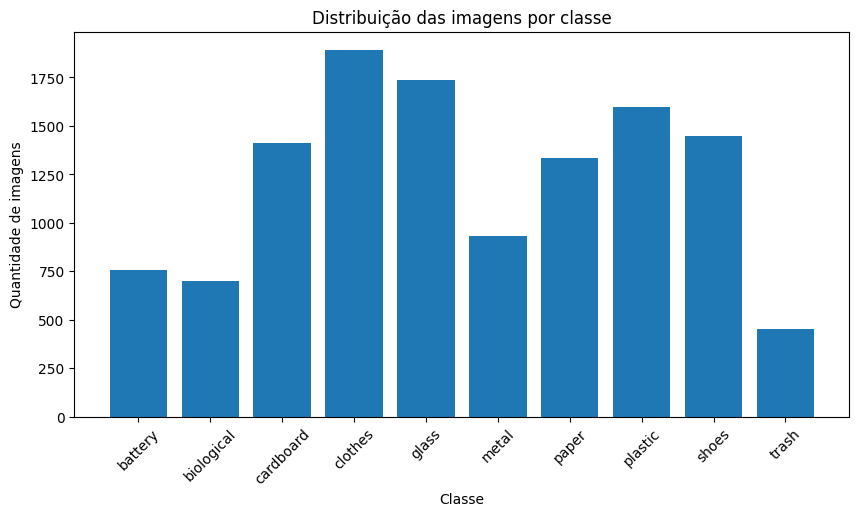

In [15]:
# Distribuição das imagens por classe (Gráfico)

plt.figure(figsize=(10,5))

plt.bar(df["Classe"], df["Quantidade"])

plt.title("Distribuição das imagens por classe")
plt.xlabel("Classe")
plt.ylabel("Quantidade de imagens")

plt.xticks(rotation=45)

# Salva o gráfico na pasta graphs do Google Drive
plt.savefig(
    "/content/drive/MyDrive/TCC/graphs/01_distribuicao_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
# Verificação de imagens corrompidas

corrompidas = []

for classe in classes:

    pasta = os.path.join(DATASET_PATH, classe)

    for arquivo in os.listdir(pasta):

        caminho = os.path.join(pasta, arquivo)

        try:
            Image.open(caminho).verify()
        except:
            corrompidas.append(caminho)

print("Imagens corrompidas:", len(corrompidas))

Imagens corrompidas: 0


In [17]:
# Análise das dimensões das imagens

larguras = []
alturas = []

for classe in classes:

    pasta = os.path.join(DATASET_PATH, classe)

    for arquivo in os.listdir(pasta):

        img = Image.open(os.path.join(pasta, arquivo))

        largura, altura = img.size

        larguras.append(largura)
        alturas.append(altura)

print("Largura mínima:", min(larguras))
print("Largura máxima:", max(larguras))

print("Altura mínima:", min(alturas))
print("Altura máxima:", max(alturas))

Largura mínima: 384
Largura máxima: 384
Altura mínima: 384
Altura máxima: 384


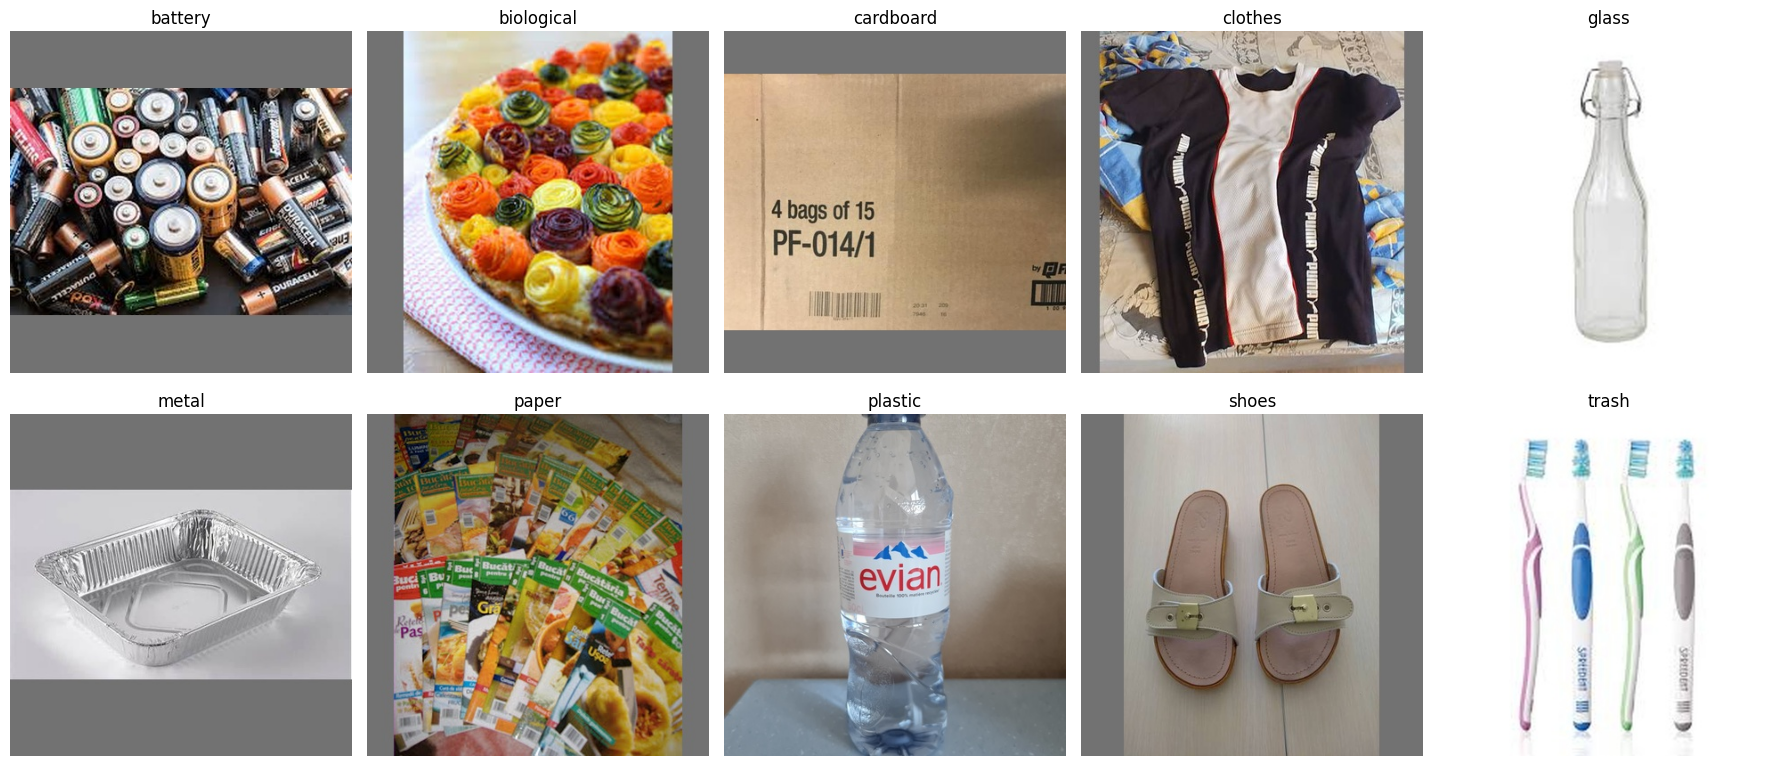

In [18]:
# Visualização de exemplos das classes

plt.figure(figsize=(18,8))

for i, classe in enumerate(classes):

    pasta = os.path.join(DATASET_PATH, classe)

    imagem = random.choice(os.listdir(pasta))

    img = Image.open(os.path.join(pasta, imagem))

    plt.subplot(2,5,i+1)
    plt.imshow(img)
    plt.title(classe)
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/TCC/graphs/02_exemplos_classes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Preparacao Dos Dados

In [19]:
# Carregamento do Dataset

train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, # This will now use BATCH_SIZE=16
    label_mode="categorical",
    shuffle=True
)

temp_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, # This will now use BATCH_SIZE=16
    label_mode="categorical",
    shuffle=False
)

Found 12259 files belonging to 10 classes.
Using 9808 files for training.
Found 12259 files belonging to 10 classes.
Using 2451 files for validation.


In [20]:
temp_dataset = temp_dataset.shuffle(
    buffer_size=tf.data.experimental.cardinality(temp_dataset).numpy(),
    seed=SEED,
    reshuffle_each_iteration=False
)

In [21]:
# Divisao em Treino, Validacao e Teste

temp_batches = tf.data.experimental.cardinality(temp_dataset).numpy()

validation_dataset = temp_dataset.take(temp_batches // 2)

test_dataset = temp_dataset.skip(temp_batches // 2)

In [22]:
# Validacao dos Batches

print("Batches de treino:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Batches de validação:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Batches de teste:", tf.data.experimental.cardinality(test_dataset).numpy())

Batches de treino: 613
Batches de validação: 77
Batches de teste: 77


In [23]:
# Classes Carregadas

class_names = train_dataset.class_names

print(class_names)

['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


In [24]:
# Formato Dos Dados

for images, labels in train_dataset.take(1):
    print("Formato das imagens:", images.shape)
    print("Formato dos labels:", labels.shape)

Formato das imagens: (16, 384, 384, 3)
Formato dos labels: (16, 10)


Data Augmentation

In [25]:
# Configuração do Data Augmentation

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

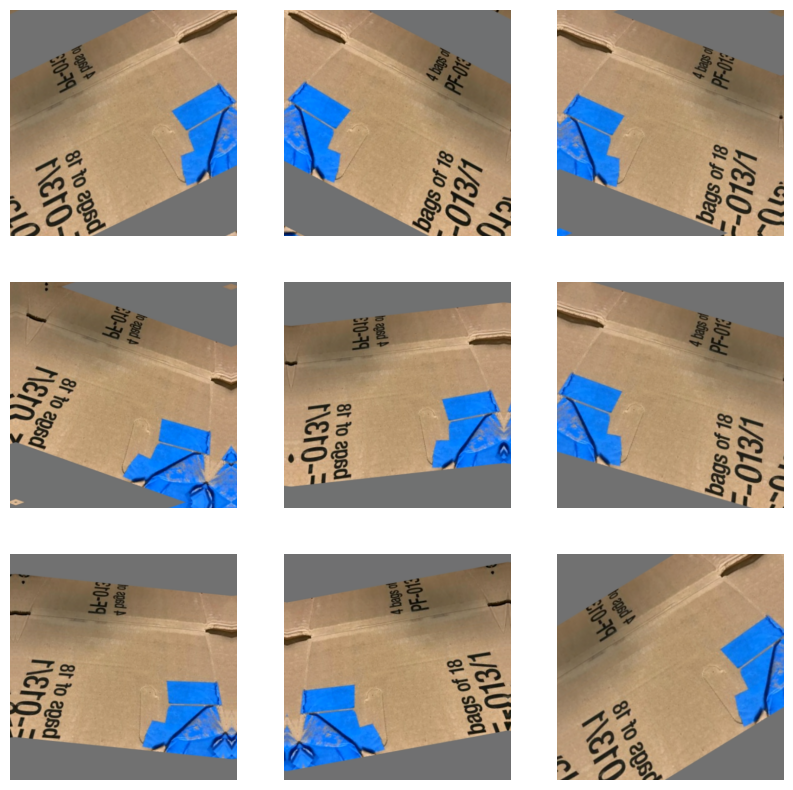

In [26]:
# Visualização das imagens aumentadas

for images, labels in train_dataset.take(1):

    image = images[0]

    plt.figure(figsize=(10,10))

    for i in range(9):
        augmented_image = data_augmentation(
            tf.expand_dims(image, axis=0),
            training=True
        )

        plt.subplot(3,3,i+1)
        plt.imshow(tf.cast(augmented_image[0], tf.uint8))
        plt.axis("off")

    plt.show()

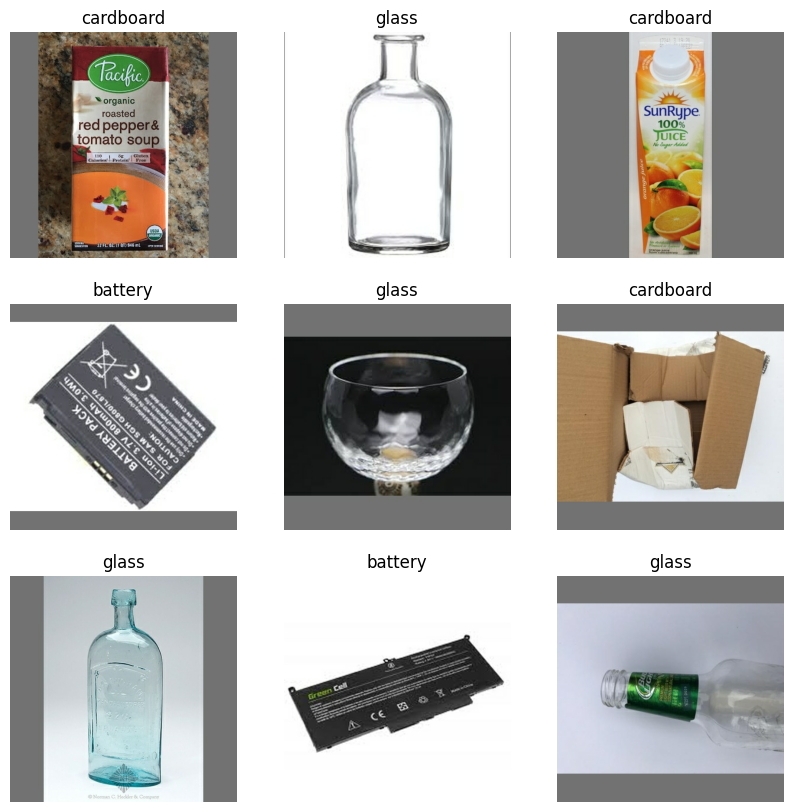

In [27]:
# Visualização das imagens aumentadas

plt.figure(figsize=(10,10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[np.argmax(labels[i])])
        plt.axis("off")

plt.show()

Otimizacao Do Pipeline

In [28]:
# Prefetch

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

Cosntrucao do Modelo

In [29]:
# Carregamento da EfficientNetV2S

base_model = EfficientNetV2S(
    include_top=False,
    weights="imagenet",
    input_shape=(384, 384, 3)
)

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [30]:
# Congelamento das camadas

base_model.trainable = False

In [31]:
# Construcao da Arquitetura

inputs = keras.Input(shape=(384,384,3))

x = base_model(inputs)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

In [32]:
# Resumo da Arquitetura

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,344,170 (77.61 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 20,331,360 (77.56 MB)

Compilacao do Modelo

In [33]:
# Compilacao

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001
)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)

In [34]:
# Conferencia de Compilacao

print(model.loss)

categorical_crossentropy


In [35]:
# Conferencia de Compilacao

print(model.optimizer)

Configuracao dos Callbacks

In [36]:
# EarlyStopping

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [37]:
# ModelCheckpoint

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(PROJECT_PATH, "models", "efficientnetv2s_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [38]:
# ReduceLROnPlateau

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

In [39]:
# Agrupamento dos Callbacks

callbacks = [
    early_stopping,
    checkpoint,
    reduce_lr
]

Treinamento do Modelo

In [40]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/2
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.7815 - loss: 0.7879
Epoch 1: val_loss improved from None to 0.21798, saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras
613/613 ━━━━━━━━━━━━━━━━━━━━ 240s 289ms/step - accuracy: 0.8745 - loss: 0.4581 - val_accuracy: 0.9368 - val_loss: 0.2180 - learning_rate: 0.0010
Epoch 2/2
613/613 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.9242 - loss: 0.2383
Epoch 2: val_loss improved from 0.21798 to 0.17185, saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/TCC/models/efficientnetv2s_best.keras
613/613 ━━━━━━━━━━━━━━━━━━━━ 102s 164ms/step - accuracy: 0.9283 - loss: 0.2278 - val_accuracy: 0.9442 - val_loss: 0.1719 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.


In [41]:
# Salvamento do historico

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(PROJECT_PATH, "history", "history_transfer_learning.csv"),
    index=False
)

print("Histórico salvo com sucesso!")

Histórico salvo com sucesso!


Avaliacao do Modelo

In [42]:
# Avaliacao do Conjunto de teste

test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)

print(f"Loss no conjunto de teste: {test_loss:.4f}")
print(f"Acurácia no conjunto de teste: {test_accuracy:.4f}")

77/77 ━━━━━━━━━━━━━━━━━━━━ 14s 139ms/step - accuracy: 0.9407 - loss: 0.1831
Loss no conjunto de teste: 0.1831
Acurácia no conjunto de teste: 0.9407


In [43]:
# Geracao das Predicoes

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model(images, training=False)

    true_classes = tf.argmax(labels, axis=1)
    predicted_classes = tf.argmax(predictions, axis=1)

    y_true.extend(true_classes.numpy().tolist())
    y_pred.extend(predicted_classes.numpy().tolist())

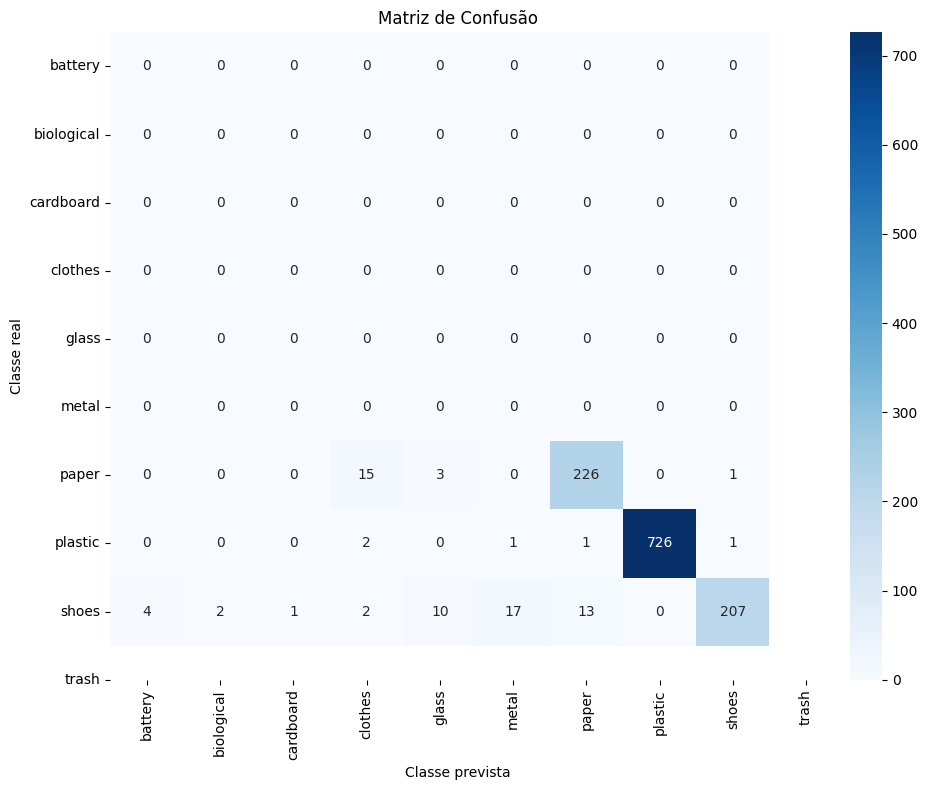

In [44]:
# Matriz de confusao

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matriz de Confusão")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")

plt.tight_layout()

plt.savefig(
    os.path.join(PROJECT_PATH, "graphs", "03_matriz_confusao.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
# Classification Report

from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

ValueError: Number of classes, 9, does not match size of target_names, 10. Try specifying the labels parameter

In [ ]:
# Salvamento do Relatorio

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    os.path.join(PROJECT_PATH, "results", "classification_report.csv")
)

report_df

In [ ]:
import numpy as np

print("Quantidade de amostras:", len(y_true))
print("Classes presentes em y_true:", np.unique(y_true))
print("Contagem por classe:")

for classe, quantidade in zip(*np.unique(y_true, return_counts=True)):
    print(f"{class_names[classe]}: {quantidade}")